# Superstore Sales & Profitability Analytics
**Tools:** Python (Pandas, NumPy, Matplotlib), SQL, Power BI

## Business objective
Understand what drives sales and profit, identify product/customer/geographic performance gaps, and assess whether discounting is associated with weaker profitability.

This notebook is designed to be run from the project root. It uses the cleaned CSV in `data/superstore_clean.csv`.

## 1. Import libraries and load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../data/superstore_clean.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/superstore_clean.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["Order Date", "Ship Date"])
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,2013-11-09,2013-11-12,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2013-152156,2013-11-09,2013-11-12,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2013-138688,2013-06-13,2013-06-17,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2012-108966,2012-10-11,2012-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2012-108966,2012-10-11,2012-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. Understand the data and validate quality

In [3]:
print("Shape:", df.shape)
display(df.info())
display(df.describe(include="all").T)
display(df.isna().sum().sort_values(ascending=False))
print("Exact duplicate rows:", df.duplicated().sum())
print("Unique orders:", df["Order ID"].nunique())
print("Unique customers:", df["Customer ID"].nunique())
print("Unique products:", df["Product ID"].nunique())

Shape: (9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Row ID,9994.0,NaN,NaN,NaN,4997.5,1.0,2499.25,4997.5,7495.75,9994.0,2885.163629
Order ID,9994,5009,CA-2014-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9994,NaN,NaN,NaN,2013-04-30 19:20:02.401441024,2011-01-04 00:00:00,2012-05-23 00:00:00,2013-06-27 00:00:00,2014-05-15 00:00:00,2014-12-31 00:00:00,NaN
Ship Date,9994,NaN,NaN,NaN,2013-05-04 18:20:49.229537792,2011-01-08 00:00:00,2012-05-27 00:00:00,2013-06-30 00:00:00,2014-05-19 00:00:00,2015-01-06 00:00:00,NaN
Ship Mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Row ID           0
Postal Code      0
Discount         0
Quantity         0
Sales            0
Product Name     0
Sub-Category     0
Category         0
Product ID       0
Region           0
State            0
Order ID         0
City             0
Country          0
Segment          0
Customer Name    0
Customer ID      0
Ship Mode        0
Ship Date        0
Order Date       0
Profit           0
dtype: int64

Exact duplicate rows: 0
Unique orders: 5009
Unique customers: 793
Unique products: 1862


### Data quality notes
- The source file was decoded using Windows-1252 and saved as UTF-8.
- Both date columns are parsed as dates.
- The provided dataset has 9,994 rows, 21 columns, no missing values, and no exact duplicate rows.
- `Row ID` is a transaction-line identifier, not an order count. Use distinct `Order ID` for orders.

## 3. Feature engineering

In [4]:
df["Year"] = df["Order Date"].dt.year
df["Quarter"] = "Q" + df["Order Date"].dt.quarter.astype(str)
df["Month Number"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.30, 0.40, 1.0],
    labels=["0%", ">0–10%", ">10–20%", ">20–30%", ">30–40%", ">40%"]
)
df["Profit Margin"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"], np.nan)
df["Loss Flag"] = df["Profit"] < 0
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Profit,Year,Quarter,Month Number,Month Name,Year-Month,Shipping Days,Discount Band,Profit Margin,Loss Flag
0,1,CA-2013-152156,2013-11-09,2013-11-12,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,41.9136,2013,Q4,11,Nov,2013-11,3,0%,0.1600,False
1,2,CA-2013-152156,2013-11-09,2013-11-12,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,219.5820,2013,Q4,11,Nov,2013-11,3,0%,0.3000,False
2,3,CA-2013-138688,2013-06-13,2013-06-17,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,6.8714,2013,Q2,6,Jun,2013-06,4,0%,0.4700,False
3,4,US-2012-108966,2012-10-11,2012-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,-383.0310,2012,Q4,10,Oct,2012-10,7,>40%,-0.4000,True
4,5,US-2012-108966,2012-10-11,2012-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,2.5164,2012,Q4,10,Oct,2012-10,7,>10–20%,0.1125,False


## 4. Executive KPIs

In [5]:
kpis = pd.Series({
    "Total Sales": df["Sales"].sum(),
    "Total Profit": df["Profit"].sum(),
    "Profit Margin": df["Profit"].sum() / df["Sales"].sum(),
    "Order Count": df["Order ID"].nunique(),
    "Customer Count": df["Customer ID"].nunique(),
    "Product Count": df["Product ID"].nunique(),
    "Units Sold": df["Quantity"].sum(),
    "Average Order Value": df["Sales"].sum() / df["Order ID"].nunique(),
    "Average Discount": df["Discount"].mean(),
    "Loss-making Rows": int(df["Loss Flag"].sum())
})
display(kpis)

Total Sales            2.297201e+06
Total Profit           2.863970e+05
Profit Margin          1.246722e-01
Order Count            5.009000e+03
Customer Count         7.930000e+02
Product Count          1.862000e+03
Units Sold             3.787300e+04
Average Order Value    4.586147e+02
Average Discount       1.562027e-01
Loss-making Rows       1.871000e+03
dtype: float64

In [6]:
print(f"Total Sales: ${kpis['Total Sales']:,.2f}")

print(f"Total Profit: ${kpis['Total Profit']:,.2f}")

print(f"Profit Margin: {kpis['Profit Margin']:.2%}")

print(f"Average Order Value: ${kpis['Average Order Value']:,.2f}")

print(f"Average Discount: {kpis['Average Discount']:.2%}")

print(f"Loss-making Rows: {kpis['Loss-making Rows']:,}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Profit Margin: 12.47%
Average Order Value: $458.61
Average Discount: 15.62%
Loss-making Rows: 1,871.0


## 5. Sales and profit trends

,Sales,Profit,Orders,Profit Margin
Year,,,,
2011,484247.4981,49543.9741,969,0.102311
2012,470532.5090,61618.6037,1038,0.130955
2013,608473.8300,81726.9308,1310,0.134315
2014,733947.0232,93507.5131,1692,0.127404


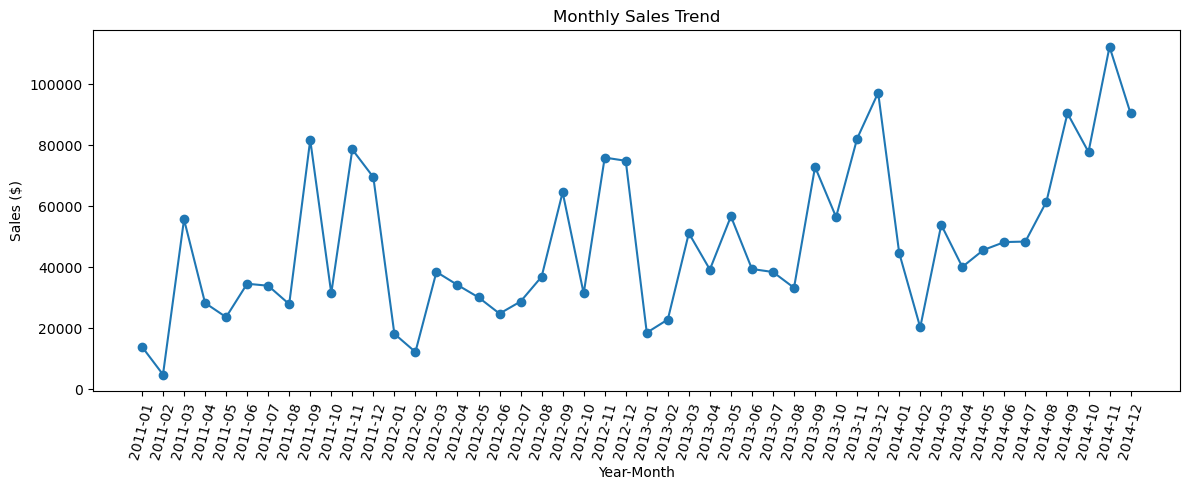

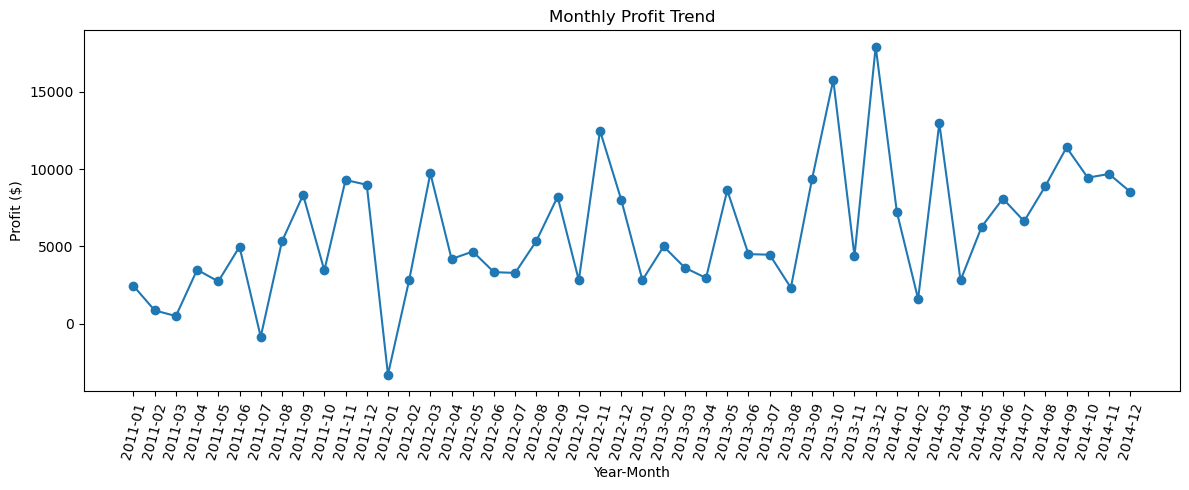

In [7]:
yearly = df.groupby("Year").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).sort_index()
yearly["Profit Margin"] = yearly["Profit"] / yearly["Sales"]
display(yearly)

monthly = df.groupby("Year-Month").agg(
    Sales=("Sales", "sum"), Profit=("Profit", "sum")
).reset_index()

plt.figure(figsize=(12,5))
plt.plot(monthly["Year-Month"], monthly["Sales"], marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month"); plt.ylabel("Sales ($)")
plt.xticks(rotation=75); plt.tight_layout(); plt.show()

plt.figure(figsize=(12,5))
plt.plot(monthly["Year-Month"], monthly["Profit"], marker="o")
plt.title("Monthly Profit Trend")
plt.xlabel("Year-Month"); plt.ylabel("Profit ($)")
plt.xticks(rotation=75); plt.tight_layout(); plt.show()

In [8]:
yearly["Sales Growth %"] = (
    yearly["Sales"].pct_change() * 100
)

yearly["Profit Growth %"] = (
    yearly["Profit"].pct_change() * 100
)

display(yearly.round(2))

,Sales,Profit,Orders,Profit Margin,Sales Growth %,Profit Growth %
Year,,,,,,
2011,484247.50,49543.97,969,0.10,NaN,NaN
2012,470532.51,61618.60,1038,0.13,-2.83,24.37
2013,608473.83,81726.93,1310,0.13,29.32,32.63
2014,733947.02,93507.51,1692,0.13,20.62,14.41


## 6. Category and sub-category profitability

In [9]:
category_perf = df.groupby("Category").agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    Quantity=("Quantity","sum"), Orders=("Order ID","nunique"),
    Avg_Discount=("Discount","mean")
)
category_perf["Profit Margin"] = category_perf["Profit"] / category_perf["Sales"]
display(category_perf.sort_values("Profit", ascending=False))

subcat = df.groupby(["Category","Sub-Category"]).agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    Quantity=("Quantity","sum"), Orders=("Order ID","nunique"),
    Avg_Discount=("Discount","mean")
)
subcat["Profit Margin"] = subcat["Profit"] / subcat["Sales"]
display(subcat.sort_values("Profit"))

,Sales,Profit,Quantity,Orders,Avg_Discount,Profit Margin
Category,,,,,,
Technology,836154.0330,145454.9481,6939,1544,0.132323,0.173957
Office Supplies,719047.0320,122490.8008,22906,3742,0.157285,0.170352
Furniture,741999.7953,18451.2728,8028,1764,0.173923,0.024867


Sales      Profit  Quantity  Orders  \
Category        Sub-Category                                              
Furniture       Tables        206965.5320 -17725.4811      1241     307   
                Bookcases     114879.9963  -3472.5560       868     224   
Office Supplies Supplies       46673.5380  -1189.0995       647     187   
                Fasteners       3024.2800    949.5182       914     215   
Technology      Machines      189238.6310   3384.7569       440     112   
Office Supplies Labels         12486.3120   5546.2540      1400     346   
                Art            27118.7920   6527.7870      3000     731   
                Envelopes      16476.4020   6964.1767       906     249   
Furniture       Furnishings    91705.1640  13059.1436      3563     877   
Office Supplies Appliances    107532.1610  18138.0054      1729     451   
                Storage       223843.6080  21278.8264      3158     777   
Furniture       Chairs        328449.1030  26590.1663      2356     576   
Office Supplies Binders       203412.7330  30221.7633      5974    1316   
                Paper          78479.2060  34053.5693      5178    1191   
Technology      Accessories   167380.3180  41936.6357      2976     718   
                Phones        330007.0540  44515.7306      3289     814   
                Copiers       149528.0300  55617.8249       234      68   

                              Avg_Discount  Profit Margin  
Category        Sub-Category                               
Furniture       Tables            0.261285      -0.085645  
                Bookcases         0.211140      -0.030228  
Office Supplies Supplies          0.076842      -0.025477  
                Fasteners         0.082028       0.313965  
Technology      Machines          0.306087       0.017886  
Office Supplies Labels            0.068681       0.444187  
                Art               0.074874       0.240711  
                Envelopes         0.080315       0.422676  
Furniture       Furnishings       0.138349       0.142404  
Office Supplies Appliances        0.166524       0.168675  
                Storage           0.074704       0.095061  
Furniture       Chairs            0.170178       0.080957  
Office Supplies Binders           0.372292       0.148574  
                Paper             0.074891       0.433918  
Technology      Accessories       0.078452       0.250547  
                Phones            0.154556       0.134893  
                Copiers           0.161765       0.371956

## 7. Product portfolio: sales versus profit

,Product ID,Product Name,Category,Sub-Category,Sales,Profit,Quantity,Orders
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.824,2.519993e+04,20,5
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,27453.384,7.753039e+03,31,10
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,-1.811078e+03,6,1
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,Chairs,21870.576,5.684342e-14,39,8
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,Binders,19823.479,2.233505e+03,37,11
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Binders,19024.500,7.609800e+02,48,9
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,18839.686,6.983884e+03,38,8
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,18374.895,4.094977e+03,12,3
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.068,-1.878166e+03,27,6
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,Office Supplies,Supplies,17030.312,-2.620048e+02,11,3


,Product ID,Product Name,Category,Sub-Category,Sales,Profit,Quantity,Orders
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.824,25199.9280,20,5
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,27453.384,7753.0390,31,10
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,18839.686,6983.8836,38,8
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,Technology,Copiers,11619.834,4570.9347,19,4
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,18374.895,4094.9766,12,3
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,Technology,Machines,7699.890,3772.9461,11,2
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,Machines,14299.890,3717.9714,11,2
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,Technology,Accessories,9367.290,3696.2820,24,7
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,Office Supplies,Binders,15875.916,3345.2823,13,3
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,Technology,Machines,6965.700,3343.5360,6,2


,Product ID,Product Name,Category,Sub-Category,Sales,Profit,Quantity,Orders
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.963,-8879.9704,9,3
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.901,-4589.9730,18,4
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.980,-3839.9904,4,1
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,9917.640,-2876.1156,27,5
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,9544.725,-1934.3976,33,7
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.068,-1878.1662,27,6
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,-1811.0784,6,1
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,Office Supplies,Supplies,16656.200,-1299.1836,22,6
346,FUR-TA-10001950,Balt Solid Wood Round Tables,Furniture,Tables,6518.754,-1201.0581,19,4
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,1706.250,-1148.4375,15,3


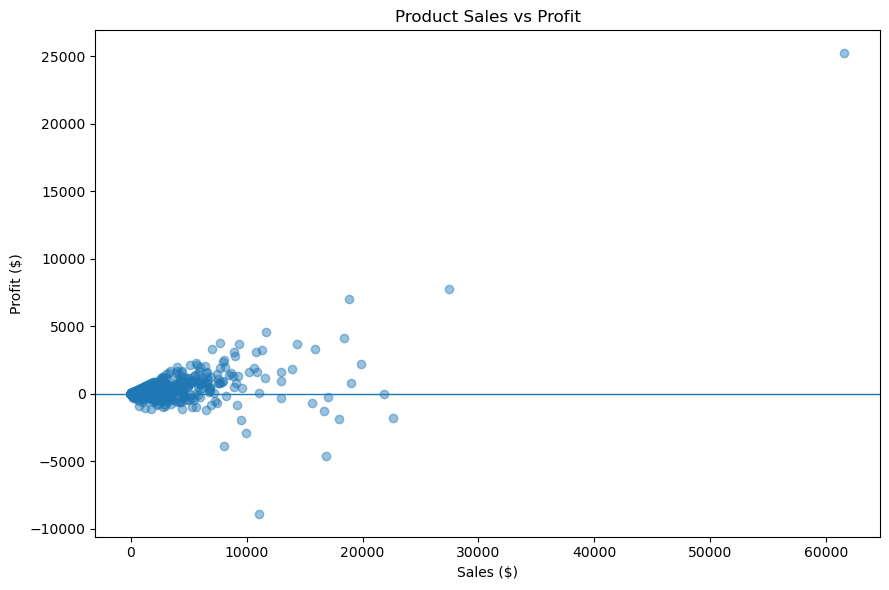

In [10]:
product_perf = df.groupby(["Product ID","Product Name","Category","Sub-Category"]).agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    Quantity=("Quantity","sum"), Orders=("Order ID","nunique")
).reset_index()
display(product_perf.nlargest(10, "Sales"))
display(product_perf.nlargest(10, "Profit"))
display(product_perf.nsmallest(10, "Profit"))

plt.figure(figsize=(9,6))
plt.scatter(product_perf["Sales"], product_perf["Profit"], alpha=0.45)
plt.axhline(0, linewidth=1)
plt.title("Product Sales vs Profit")
plt.xlabel("Sales ($)"); plt.ylabel("Profit ($)")
plt.tight_layout(); plt.show()

In [11]:

# Calculate product-level profit margin

product_perf["Profit Margin"] = (
    product_perf["Profit"] / product_perf["Sales"] * 100
)

# Top 10 products by profit margin
display(
    product_perf.nlargest(10, "Profit Margin")[
        ["Product Name", "Sales", "Profit", "Profit Margin"]
    ]
)

# Bottom 10 products by profit margin
display(
    product_perf.nsmallest(10, "Profit Margin")[
        ["Product Name", "Sales", "Profit", "Profit Margin"]
    ]
)


,Product Name,Sales,Profit,Profit Margin
1002,Avery 475,266.40,133.2000,50.0
1192,Xerox 1890,244.70,122.3500,50.0
1270,Adams Telephone Message Book w/Frequently-Call...,223.44,111.7200,50.0
1271,Tops Green Bar Computer Printout Paper,342.58,171.2900,50.0
1299,Southworth Structures Collection,72.80,36.4000,50.0
1674,Canon imageCLASS MF7460 Monochrome Digital Las...,3991.98,1995.9900,50.0
1001,Avery 5,5.76,2.8224,49.0
1074,Staples,279.90,137.1510,49.0
1094,Xerox 1918,155.04,75.9696,49.0
871,"Strathmore #10 Envelopes, Ultimate White",632.52,309.9348,49.0


,Product Name,Sales,Profit,Profit Margin
427,Eureka Disposable Bags for Sanitaire Vibra Gro...,1.624,-4.4660,-275.000000
8,"Bush Westfield Collection Bookcases, Dark Cher...",90.882,-190.8522,-210.000000
394,Euro Pro Shark Stick Mini Vacuum,170.744,-325.6332,-190.714286
1685,Okidata B401 Printer,179.991,-251.9874,-140.000000
1662,Zebra GK420t Direct Thermal/Thermal Transfer P...,703.710,-938.2800,-133.333333
775,GBC Plasticlear Binding Covers,68.880,-68.4208,-99.333333
1652,"Brother MFC-9340CDW LED All-In-One Printer, Co...",341.991,-319.1916,-93.333333
1668,Epson TM-T88V Direct Thermal Printer - Monochr...,1212.705,-1057.2300,-87.179487
1701,Epson Perfection V600 Photo Scanner,206.991,-172.4925,-83.333333
675,GBC VeloBinder Electric Binding Machine,496.018,-411.3320,-82.926829


## 8. Customer analysis

In [12]:
customer_perf = df.groupby(["Customer ID","Customer Name","Segment"]).agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    Orders=("Order ID","nunique"), Quantity=("Quantity","sum"),
    Avg_Discount=("Discount","mean")
).reset_index()
customer_perf["AOV"] = customer_perf["Sales"] / customer_perf["Orders"]
customer_perf["Profit Margin"] = customer_perf["Profit"] / customer_perf["Sales"]
display(customer_perf.nlargest(10, "Sales"))
display(customer_perf.nlargest(10, "Profit"))
display(customer_perf.nsmallest(10, "Profit"))

segment_perf = df.groupby("Segment").agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    Orders=("Order ID","nunique"), Customers=("Customer ID","nunique")
)
segment_perf["Profit Margin"] = segment_perf["Profit"] / segment_perf["Sales"]
display(segment_perf)

,Customer ID,Customer Name,Segment,Sales,Profit,Orders,Quantity,Avg_Discount,AOV,Profit Margin
700,SM-20320,Sean Miller,Home Office,25043.050,-1980.7393,5,50,0.246667,5008.610000,-0.079093
741,TC-20980,Tamara Chand,Corporate,19052.218,8981.3239,5,42,0.116667,3810.443600,0.471406
621,RB-19360,Raymond Buch,Consumer,15117.339,6976.0959,6,71,0.094444,2519.556500,0.461463
730,TA-21385,Tom Ashbrook,Home Office,14595.620,4703.7883,4,36,0.080000,3648.905000,0.322274
6,AB-10105,Adrian Barton,Consumer,14473.571,5444.8055,10,73,0.240000,1447.357100,0.376190
434,KL-16645,Ken Lonsdale,Consumer,14175.229,806.8550,12,113,0.200000,1181.269083,0.056920
669,SC-20095,Sanjit Chand,Consumer,14142.334,5757.4119,9,87,0.063636,1571.370444,0.407105
327,HL-15040,Hunter Lopez,Consumer,12873.298,5622.4292,6,50,0.018182,2145.549667,0.436751
683,SE-20110,Sanjit Engle,Consumer,12209.438,2650.6769,11,78,0.110526,1109.948909,0.217101
131,CC-12370,Christopher Conant,Consumer,12129.072,2177.0493,5,34,0.281818,2425.814400,0.179490


,Customer ID,Customer Name,Segment,Sales,Profit,Orders,Quantity,Avg_Discount,AOV,Profit Margin
741,TC-20980,Tamara Chand,Corporate,19052.218,8981.3239,5,42,0.116667,3810.443600,0.471406
621,RB-19360,Raymond Buch,Consumer,15117.339,6976.0959,6,71,0.094444,2519.556500,0.461463
669,SC-20095,Sanjit Chand,Consumer,14142.334,5757.4119,9,87,0.063636,1571.370444,0.407105
327,HL-15040,Hunter Lopez,Consumer,12873.298,5622.4292,6,50,0.018182,2145.549667,0.436751
6,AB-10105,Adrian Barton,Consumer,14473.571,5444.8055,10,73,0.240000,1447.357100,0.376190
730,TA-21385,Tom Ashbrook,Home Office,14595.620,4703.7883,4,36,0.080000,3648.905000,0.322274
160,CM-12385,Christopher Martinez,Consumer,8954.020,3899.8904,4,34,0.120000,2238.505000,0.435546
424,KD-16495,Keith Dawkins,Corporate,8181.256,3038.6254,12,84,0.087500,681.771333,0.371413
48,AR-10540,Andy Reiter,Consumer,6608.448,2884.6208,6,33,0.066667,1101.408000,0.436505
234,DR-12940,Daniel Raglin,Home Office,8350.868,2869.0760,8,57,0.153846,1043.858500,0.343566


,Customer ID,Customer Name,Segment,Sales,Profit,Orders,Quantity,Avg_Discount,AOV,Profit Margin
180,CS-12505,Cindy Stewart,Consumer,5690.055,-6626.3895,6,40,0.200000,948.342500,-1.164556
310,GT-14635,Grant Thornton,Corporate,9351.212,-4108.6589,3,26,0.250000,3117.070667,-0.439372
459,LF-17185,Luke Foster,Consumer,3930.509,-3583.9770,7,69,0.318750,561.501286,-0.911835
711,SR-20425,Sharelle Roach,Home Office,3233.481,-3333.9144,5,34,0.366667,646.696200,-1.031060
322,HG-14965,Henry Goldwyn,Corporate,3247.642,-2797.9635,12,68,0.170588,270.636833,-0.861537
555,NC-18415,Nathan Cano,Consumer,2218.990,-2204.8072,6,38,0.264286,369.831667,-0.993608
666,SB-20290,Sean Braxton,Corporate,8057.891,-2082.7451,7,84,0.241176,1151.127286,-0.258473
700,SM-20320,Sean Miller,Home Office,25043.050,-1980.7393,5,50,0.246667,5008.610000,-0.079093
165,CP-12340,Christine Phan,Corporate,5888.275,-1850.3029,8,59,0.213333,736.034375,-0.314235
560,NF-18385,Natalie Fritzler,Consumer,8322.826,-1695.9714,7,52,0.250000,1188.975143,-0.203774


,Sales,Profit,Orders,Customers,Profit Margin
Segment,,,,,
Consumer,1.161401e+06,134119.2092,2586,409,0.115481
Corporate,7.061464e+05,91979.1340,1514,236,0.130255
Home Office,4.296531e+05,60298.6785,909,148,0.140343


In [13]:

segment_perf["Sales Contribution %"] = (
    segment_perf["Sales"] / segment_perf["Sales"].sum() * 100
)

segment_perf["Profit Contribution %"] = (
    segment_perf["Profit"] / segment_perf["Profit"].sum() * 100
)

display(segment_perf.round(2))


,Sales,Profit,Orders,Customers,Profit Margin,Sales Contribution %,Profit Contribution %
Segment,,,,,,,
Consumer,1161401.34,134119.21,2586,409,0.12,50.56,46.83
Corporate,706146.37,91979.13,1514,236,0.13,30.74,32.12
Home Office,429653.15,60298.68,909,148,0.14,18.70,21.05


## 9. Geographic performance

In [14]:
geo = df.groupby(["Region","State"]).agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    Orders=("Order ID","nunique"), Customers=("Customer ID","nunique"),
    Avg_Discount=("Discount","mean")
).reset_index()
geo["Profit Margin"] = geo["Profit"] / geo["Sales"]
display(geo.nlargest(10, "Profit"))
display(geo.nsmallest(10, "Profit"))

region_perf = df.groupby("Region").agg(
    Sales=("Sales","sum"), Profit=("Profit","sum"),
    Orders=("Order ID","nunique")
)
region_perf["Profit Margin"] = region_perf["Profit"] / region_perf["Sales"]
display(region_perf.sort_values("Profit", ascending=False))

,Region,State,Sales,Profit,Orders,Customers,Avg_Discount,Profit Margin
39,West,California,457687.6315,76381.3871,1021,577,0.072764,0.166885
21,East,New York,310876.2710,74038.5486,562,415,0.055319,0.238161
47,West,Washington,138641.2700,33402.6517,256,224,0.064032,0.240929
4,Central,Michigan,76269.6140,24463.1876,117,106,0.007059,0.320746
37,South,Virginia,70636.7200,18597.9504,115,107,0.000000,0.263290
1,Central,Indiana,53555.3600,18382.9363,73,70,0.000000,0.343251
30,South,Georgia,49095.8400,16250.0433,91,83,0.000000,0.330986
31,South,Kentucky,36591.7500,11199.6966,61,58,0.000000,0.306072
5,Central,Minnesota,29863.1500,10823.1874,44,42,0.000000,0.362426
14,East,Delaware,27451.0690,9977.3748,44,43,0.006250,0.363460


,Region,State,Sales,Profit,Orders,Customers,Avg_Discount,Profit Margin
11,Central,Texas,170188.0458,-25729.3563,487,370,0.370193,-0.151182
22,East,Ohio,78258.1360,-16971.3766,236,202,0.324947,-0.216864
23,East,Pennsylvania,116511.9140,-15559.9603,288,257,0.328620,-0.133548
0,Central,Illinois,80166.1010,-12607.8870,276,237,0.390041,-0.157272
34,South,North Carolina,55603.1640,-7490.9122,136,122,0.283534,-0.134721
40,West,Colorado,32108.1180,-6527.8579,79,75,0.316484,-0.203309
36,South,Tennessee,30661.8730,-5341.6936,91,84,0.291257,-0.174213
38,West,Arizona,35282.0010,-3427.9246,108,100,0.303571,-0.097158
29,South,Florida,89473.7080,-3399.3017,200,181,0.299347,-0.037992
45,West,Oregon,17431.1500,-1190.4705,56,51,0.288710,-0.068296


,Sales,Profit,Orders,Profit Margin
Region,,,,
West,725457.8245,108418.4489,1611,0.149448
East,678781.2400,91522.7800,1401,0.134834
South,391721.9050,46749.4303,822,0.119343
Central,501239.8908,39706.3625,1175,0.079216


## 10. Discount and profitability

,Rows,Sales,Profit,Orders,Profit Margin
Discount Band,,,,,
0%,4798,1.087908e+06,320987.6032,2644,0.295050
>0–10%,94,5.436935e+04,9029.1770,89,0.166071
>10–20%,3709,7.921529e+05,91756.2975,2436,0.115832
>20–30%,227,1.032267e+05,-10369.2774,211,-0.100452
>30–40%,233,1.309112e+05,-25448.1881,211,-0.194393
>40%,933,1.286323e+05,-99558.5905,737,-0.773978


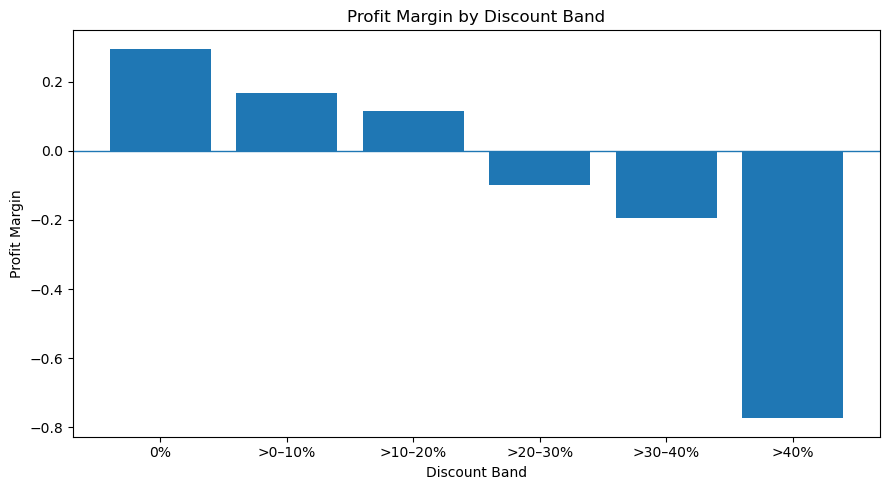

Correlation (row-level discount vs profit): -0.21948745637176895


In [15]:
discount_perf = df.groupby("Discount Band", observed=False).agg(
    Rows=("Row ID","count"), Sales=("Sales","sum"),
    Profit=("Profit","sum"), Orders=("Order ID","nunique")
)
discount_perf["Profit Margin"] = discount_perf["Profit"] / discount_perf["Sales"]
display(discount_perf)

plt.figure(figsize=(9,5))
plt.bar(discount_perf.index.astype(str), discount_perf["Profit Margin"])
plt.axhline(0, linewidth=1)
plt.title("Profit Margin by Discount Band")
plt.xlabel("Discount Band"); plt.ylabel("Profit Margin")
plt.tight_layout(); plt.show()

# Descriptive association only; discount is not randomly assigned.
print("Correlation (row-level discount vs profit):", df["Discount"].corr(df["Profit"]))

In [16]:

discount_summary = df.groupby("Discount Band", observed=False).agg(
    Average_Discount=("Discount", "mean"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Transaction_Count=("Row ID", "count")
)

discount_summary["Profit_Margin"] = (
    discount_summary["Total_Profit"] /
    discount_summary["Total_Sales"] * 100
)

display(discount_summary.round(2))


,Average_Discount,Total_Sales,Total_Profit,Transaction_Count,Profit_Margin
Discount Band,,,,,
0%,0.00,1087908.47,320987.60,4798,29.51
>0–10%,0.10,54369.35,9029.18,94,16.61
>10–20%,0.20,792152.89,91756.30,3709,11.58
>20–30%,0.30,103226.66,-10369.28,227,-10.05
>30–40%,0.39,130911.24,-25448.19,233,-19.44
>40%,0.70,128632.25,-99558.59,933,-77.40


**Interpretation caution:** Discount and profit are associated in this observational dataset, but this alone does not prove that discounts caused the profit outcome. Product mix, order size, category and region can also affect the relationship. Compare within category/sub-category and avoid causal wording.

## 11. Shipping analysis

In [17]:
shipping_perf = df.groupby("Ship Mode").agg(
    Orders=("Order ID","nunique"), Sales=("Sales","sum"),
    Profit=("Profit","sum"), Avg_Shipping_Days=("Shipping Days","mean")
)
shipping_perf["Profit Margin"] = shipping_perf["Profit"] / shipping_perf["Sales"]
display(shipping_perf.sort_values("Avg_Shipping_Days"))

,Orders,Sales,Profit,Avg_Shipping_Days,Profit Margin
Ship Mode,,,,,
Same Day,264,1.283631e+05,15891.7589,0.044199,0.123803
First Class,787,3.514284e+05,48969.8399,2.182055,0.139345
Second Class,964,4.591936e+05,57446.6354,3.240103,0.125103
Standard Class,2994,1.358216e+06,164088.7875,5.007205,0.120812


## 12. Cross-analysis

In [18]:
# Segment x Category
segment_category = df.pivot_table(
    index="Segment", columns="Category", values="Sales",
    aggfunc="sum", fill_value=0
)
display(segment_category)

# Region x Category profitability
region_category = df.pivot_table(
    index="Region", columns="Category", values="Profit",
    aggfunc="sum", fill_value=0
)
display(region_category)

# Category x discount band
category_discount = df.pivot_table(
    index="Category", columns="Discount Band", values="Profit",
    aggfunc="sum", fill_value=0, observed=False
)
display(category_discount)

Category,Furniture,Office Supplies,Technology
Segment,,,
Consumer,391049.3120,363952.136,406399.897
Corporate,229019.7858,230676.462,246450.119
Home Office,121930.6975,124418.434,183304.017


Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.0494,8879.9799,33697.4320
East,3046.1658,41014.5791,47462.0351
South,6771.2061,19986.3928,19991.8314
West,11504.9503,52609.8490,44303.6496


Discount Band,0%,>0–10%,>10–20%,>20–30%,>30–40%,>40%
Category,,,,,,
Furniture,58133.0764,7111.0119,7684.9406,-10695.3169,-18578.5345,-25203.9047
Office Supplies,130506.1064,1086.0808,38038.7512,0.0000,0.0000,-47140.1376
Technology,132348.4204,832.0843,46032.6057,326.0395,-6869.6536,-27214.5482


## 13. Export analytical tables for Power BI

In [19]:
export_dir = Path("../outputs")
if not export_dir.exists():
    export_dir = Path("outputs")
export_dir.mkdir(exist_ok=True)

tables = {
    "category_performance": category_perf.reset_index(),
    "subcategory_performance": subcat.reset_index(),
    "product_performance": product_perf,
    "customer_performance": customer_perf,
    "regional_performance": region_perf.reset_index(),
    "state_performance": geo,
    "discount_performance": discount_perf.reset_index(),
    "shipping_performance": shipping_perf.reset_index(),
    "yearly_performance": yearly.reset_index()
}
for name, table in tables.items():
    table.to_csv(export_dir / f"{name}.csv", index=False)
print("Exported", len(tables), "analysis tables to", export_dir)

Exported 9 analysis tables to outputs


## 14. Final business interpretation checklist

Use the actual outputs above to write conclusions:
1. Which category generates the most sales and which generates the most profit?
2. Which sub-categories have negative total profit?
3. Which states have the largest positive and negative profit?
4. How does profit margin vary across discount bands?
5. Which customer segment contributes the most sales and profit?
6. How do yearly sales and profit change?
7. Which shipping mode has the shortest/longest average delivery time?

For each insight, report the metric, comparison, likely business implication, and a practical recommendation. Do not claim that an analysis increased revenue or profit because this project does not implement a real intervention.